# Examen Parcial - Informe 03 - Redes Neuronales Aprendizaje Profundo - Grupo 07
---
**Crisanto Palacios, Eduardo**
**Riveros Ruiz, Jason Wilmer**
**Torres Vela, Juan Carlos (Representante)**
**Zavala Suyo, Rafael**

---
**Prof. Dr.    Aldo Camargo**

---
# 01 · Datos CCT-20: descarga, EDA y conversión a formato YOLO

**Proyecto:** Monitoreo de fauna silvestre con cámaras trampa (YOLO) · Dataset: *Caltech Camera Traps* (LILA BC)

Este notebook:
1. Descarga las anotaciones oficiales (imagen-nivel, *bounding boxes* y partición `eccv_train` / `eccv_val`).
2. Hace el análisis exploratorio (desbalance, vacías vs. fauna, especificidad de especies por cámara, tamaño de animales).
3. Construye tres particiones **por ubicación de cámara y por secuencia** (evita fuga de información):
   - `train` y `cis_val`: ubicaciones de `eccv_train` (mismas cámaras, secuencias distintas).
   - `trans_val`: ubicaciones de `eccv_val` (**cámaras nunca vistas** en entrenamiento).
4. Descarga *solo* las imágenes necesarias (no los 105 GB), las reduce a 640 px y escribe las etiquetas YOLO.

> - Una imagen con animal **sin** bounding box *no* se usa como fondo (sería un falso negativo en las etiquetas). Solo son fondo las imágenes marcadas `empty`.
> - Las imágenes de una misma ráfaga (secuencia) nunca quedan repartidas entre `train` y `cis_val`.
> - Las particiones de evaluación conservan la mezcla natural de vacías/fauna; `train` limita las vacías (parámetro `EMPTY_FRAC_TRAIN`) para no ahogar a las clases raras.

In [ ]:
!pip -q install -U ultralytics
import ultralytics
print('ultralytics', ultralytics.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 77.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 11.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
ultralytics 8.4.184


In [ ]:
import os, sys, io, json, math, random, zipfile, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image, ImageDraw
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive')

DRIVE_DIR = Path('/content/drive/MyDrive/Dfoto')
LOCAL = Path('/content/cct')
os.environ['CCT_DRIVE_DIR'] = str(DRIVE_DIR)
os.environ['CCT_LOCAL'] = str(LOCAL)
DRIVE_DIR.mkdir(parents=True, exist_ok=True)
LOCAL.mkdir(parents=True, exist_ok=True)

UTILS_SRC = r'''"""Utilidades compartidas por los notebooks del proyecto CCT-20 + YOLO.

Se guarda en Google Drive (carpeta cct_yolo) y los notebooks 02-04 la importan
con `import cct_utils as U`.
"""
import os
import re
import json
import math
import random
import shutil
import subprocess
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd

DRIVE_DIR = Path(os.environ.get('CCT_DRIVE_DIR', '/content/drive/MyDrive/Dfoto'))
LOCAL = Path(os.environ.get('CCT_LOCAL', '/content/cct'))
IMGSZ = 640
SEED = 42
CLASSES = []


# ----------------------------------------------------------------------------
# Entorno
# ----------------------------------------------------------------------------
def init():
    """Crea carpetas, fija semillas y carga la lista de clases (si ya existe)."""
    DRIVE_DIR.mkdir(parents=True, exist_ok=True)
    LOCAL.mkdir(parents=True, exist_ok=True)
    seed_all()
    cls_path = DRIVE_DIR / 'metadata' / 'classes.json'
    if cls_path.exists():
        load_classes()


def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


def load_classes():
    global CLASSES
    with open(DRIVE_DIR / 'metadata' / 'classes.json') as f:
        CLASSES = json.load(f)
    return CLASSES


def ensure_dataset():
    """Si el disco local de Colab fue reiniciado, restaura el dataset desde Drive."""
    train_dir = LOCAL / 'images' / 'train'
    if train_dir.exists() and any(train_dir.iterdir()):
        return
    tar = DRIVE_DIR / 'cct_dataset.tar'
    if not tar.exists():
        raise FileNotFoundError(
            'No hay dataset local ni cct_dataset.tar en Drive. Ejecuta primero el notebook 01.')
    print('Restaurando dataset desde Drive (puede tardar unos minutos)...')
    LOCAL.mkdir(parents=True, exist_ok=True)
    subprocess.run(['tar', '-xf', str(tar), '-C', str(LOCAL)], check=True)
    print('Dataset restaurado en', LOCAL)


def load_meta():
    meta = pd.read_csv(DRIVE_DIR / 'metadata' / 'meta.csv', dtype={'location': str})
    meta['datetime'] = pd.to_datetime(meta['datetime'], errors='coerce')
    meta['species'] = meta['species'].fillna('')
    return meta


def location_of(filename):
    m = re.match(r'loc(.+?)__', filename)
    return m.group(1) if m else None


def make_yaml(name, train, val):
    """Crea un data.yaml de Ultralytics. `train` puede ser str o lista de carpetas."""
    import yaml
    d = {'path': str(LOCAL), 'train': train, 'val': val,
         'names': {i: c for i, c in enumerate(CLASSES)}}
    p = LOCAL / f'{name}.yaml'
    with open(p, 'w') as f:
        yaml.safe_dump(d, f, sort_keys=False)
    return p


def count_instances(split):
    """Cuenta instancias (cajas) por clase en las etiquetas de un split."""
    cnt = Counter()
    for lab in (LOCAL / 'labels' / split).glob('*.txt'):
        for line in lab.read_text().splitlines():
            if line.strip():
                cnt[CLASSES[int(line.split()[0])]] += 1
    return cnt


# ----------------------------------------------------------------------------
# Desbalance: Repeat Factor Sampling (Gupta et al., LVIS) materializado en disco
# ----------------------------------------------------------------------------
def build_rfs_dir(meta_train, t=0.05, rmax=6, src='train', dst='train_rfs', seed=SEED):
    """Crea images/<dst> y labels/<dst> con enlaces simbolicos a las imagenes de <src>,
    repitiendo las que contienen especies raras.

    r_c = max(1, sqrt(t / f_c)), con f_c = fraccion de imagenes de entrenamiento que
    contienen la clase c. El factor de una imagen es el maximo de sus clases (tope rmax).
    Se usan nombres distintos (__repN) para que ningun cargador deduplique.
    """
    rng = np.random.default_rng(seed)
    sp = meta_train['species'].apply(lambda s: [c for c in str(s).split('|') if c])
    n = len(meta_train)
    freq = Counter(c for cl in sp for c in set(cl))
    r_c = {c: max(1.0, math.sqrt(t / (freq[c] / n))) for c in freq}

    img_dst = LOCAL / 'images' / dst
    lab_dst = LOCAL / 'labels' / dst
    for d in (img_dst, lab_dst):
        if d.exists():
            shutil.rmtree(d)
        d.mkdir(parents=True)
    n_extra = 0
    for f, cl in zip(meta_train['file'], sp):
        r = min(max([r_c[c] for c in cl], default=1.0), rmax)
        k = int(r) + int(rng.random() < (r - int(r)))
        k = max(k, 1)
        stem = Path(f).stem
        for j in range(k):
            suf = '' if j == 0 else f'__rep{j}'
            os.symlink(LOCAL / 'images' / src / f, img_dst / f'{stem}{suf}.jpg')
            shutil.copy(LOCAL / 'labels' / src / f'{stem}.txt', lab_dst / f'{stem}{suf}.txt')
        n_extra += k - 1
    return r_c, n_extra


# ----------------------------------------------------------------------------
# Evaluacion
# ----------------------------------------------------------------------------
def eval_detector(weights, split, tag, conf=0.001, iou=0.6, batch=32):
    """Evaluacion COCO-style de Ultralytics sobre images/<split>."""
    from ultralytics import YOLO
    m = YOLO(str(weights))
    yml = make_yaml(f'eval_{split}', 'images/train', f'images/{split}')
    r = m.val(data=str(yml), imgsz=IMGSZ, batch=batch, conf=conf, iou=iou, plots=True,
              project=str(DRIVE_DIR / 'eval'), name=f'{tag}_{split}', exist_ok=True,
              verbose=False)
    out = {'split': split, 'map50': float(r.box.map50), 'map50_95': float(r.box.map),
           'precision': float(r.box.mp), 'recall': float(r.box.mr), 'per_class': {}}
    for i, ci in enumerate(r.box.ap_class_index):
        p, rc, ap50, ap = r.box.class_result(i)
        out['per_class'][CLASSES[int(ci)]] = dict(
            p=float(p), r=float(rc), ap50=float(ap50), ap=float(ap))
    return out


def predict_split(weights, split, tag, conf=0.05, iou=0.6, batch=64, force=False):
    """Predice todas las imagenes de un split y guarda las detecciones en Drive (CSV).

    Las imagenes sin detecciones no generan filas: se consideran 'vacias'.
    """
    out_csv = DRIVE_DIR / 'preds' / f'{tag}_{split}.csv'
    if out_csv.exists() and not force:
        return pd.read_csv(out_csv)
    from ultralytics import YOLO
    m = YOLO(str(weights))
    files = sorted((LOCAL / 'images' / split).glob('*.jpg'))
    rows = []
    for i in range(0, len(files), batch):
        chunk = files[i:i + batch]
        res = m.predict([str(f) for f in chunk], conf=conf, iou=iou, imgsz=IMGSZ, verbose=False)
        for f, r in zip(chunk, res):
            b = r.boxes
            if b is None or len(b) == 0:
                continue
            xyxyn = b.xyxyn.cpu().numpy()
            c = b.cls.cpu().numpy().astype(int)
            s = b.conf.cpu().numpy()
            for k in range(len(c)):
                rows.append((f.name, CLASSES[c[k]], float(s[k]), *[float(v) for v in xyxyn[k]]))
    df = pd.DataFrame(rows, columns=['file', 'cls', 'conf', 'x1', 'y1', 'x2', 'y2'])
    out_csv.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(out_csv, index=False)
    return df


def image_level_metrics(M, preds, thr, exclude=()):
    """Metricas 'hay fauna / no hay fauna' por imagen (lo que importa para filtrar vacias)."""
    gt = (M.set_index('file')['n_boxes'] > 0)
    P = preds[(preds['conf'] >= thr) & (~preds['cls'].isin(exclude))]
    pred = pd.Series(gt.index.isin(P['file'].unique()), index=gt.index)
    tp = int((pred & gt).sum())
    fp = int((pred & ~gt).sum())
    fn = int((~pred & gt).sum())
    tn = int((~pred & ~gt).sum())
    prec = tp / max(tp + fp, 1)
    rec = tp / max(tp + fn, 1)
    f1 = 2 * prec * rec / max(prec + rec, 1e-9)
    return dict(thr=thr, tp=tp, fp=fp, fn=fn, tn=tn, precision=prec, recall=rec, f1=f1,
                empty_false_alarm=fp / max(fp + tn, 1))


def sweep_image_level(M, preds, grid=None):
    grid = np.arange(0.05, 0.96, 0.05) if grid is None else grid
    return pd.DataFrame([image_level_metrics(M, preds, float(t)) for t in grid])


def per_location_image_metrics(M, preds, thr):
    rows = []
    for loc, g in M.groupby('location'):
        d = image_level_metrics(g, preds[preds['file'].isin(g['file'])], thr)
        d['location'] = loc
        d['n_images'] = len(g)
        rows.append(d)
    return pd.DataFrame(rows)
'''
(DRIVE_DIR / 'cct_utils.py').write_text(UTILS_SRC)
print('cct_utils.py guardado en', DRIVE_DIR)

sys.path.insert(0, str(DRIVE_DIR))
import cct_utils as U
U.seed_all()

Mounted at /content/drive
cct_utils.py guardado en /content/drive/MyDrive/Dfoto


## 1. Configuración
Ajusta estos parámetros

In [ ]:
CFG = dict(
    MAX_SIDE=640,             # lado mayor de las imágenes guardadas
    MAX_ANIMAL_PER_LOC=1500,  # tope de imágenes CON animal por cámara de entrenamiento
    EMPTY_FRAC_TRAIN=0.15,    # fracción de imágenes vacías (fondo) en train
    EVAL_MAX_PER_LOC=1000,    # tope de imágenes por cámara en cis_val / trans_val (mezcla natural)
    CIS_FRAC=0.15,            # fracción de secuencias de las cámaras de train reservada para cis_val
    N_WORKERS=32,             # hilos de descarga
    SAVE_TAR_TO_DRIVE=True,   # guarda cct_dataset.tar en Drive para restaurar rápido en otras sesiones
    SEED=42,
)
rng = np.random.default_rng(CFG['SEED'])
json.dump(CFG, open(DRIVE_DIR / 'config_dataset.json', 'w'), indent=2)

## 2. Descarga de metadatos oficiales (LILA BC)
- Anotaciones a nivel imagen: `caltech_camera_traps.json.zip` (formato COCO Camera Traps)
- Bounding boxes: `caltech_bboxes_20200316.json`
- Particiones recomendadas: `CaltechCameraTrapsSplits_v0.json` (`eccv_train` = ubicaciones *train+cis* del paper ECCV 2018; `eccv_val` = ubicaciones *trans*).

In [ ]:
GCS = 'https://storage.googleapis.com/public-datasets-lila/caltechcameratraps'
IMG_BASE = 'https://storage.googleapis.com/public-datasets-lila/caltech-unzipped/cct_images/'
URLS = {
    'img_labels_zip': f'{GCS}/labels/caltech_camera_traps.json.zip',
    'bboxes': f'{GCS}/labels/caltech_bboxes_20200316.json',
    'splits': f'{GCS}/CaltechCameraTrapsSplits_v0.json',
}
META_DIR = DRIVE_DIR / 'metadata'
META_DIR.mkdir(exist_ok=True)

def download(url, dst):
    dst = Path(dst)
    if dst.exists() and dst.stat().st_size > 0:
        return dst
    with requests.get(url, stream=True, timeout=180) as r:
        r.raise_for_status()
        with open(dst, 'wb') as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
    return dst

zpath = download(URLS['img_labels_zip'], META_DIR / 'caltech_camera_traps.json.zip')
with zipfile.ZipFile(zpath) as z:
    jname = [n for n in z.namelist() if n.endswith('.json')][0]
    img_json = json.load(z.open(jname))
bb_json = json.load(open(download(URLS['bboxes'], META_DIR / 'caltech_bboxes_20200316.json')))
splits = json.load(open(download(URLS['splits'], META_DIR / 'CaltechCameraTrapsSplits_v0.json')))['splits']

print('claves imagen-nivel :', list(img_json.keys()))
print('claves bboxes       :', list(bb_json.keys()))
print('particiones         :', {k: len(set(v)) for k, v in splits.items()}, '(ubicaciones únicas)')

claves imagen-nivel : ['images', 'annotations', 'categories', 'info']
claves bboxes       : ['info', 'categories', 'annotations', 'images']
particiones         : {'train': 100, 'val': 40, 'eccv_train': 10, 'eccv_val': 10} (ubicaciones únicas)


## 3. Tablas de trabajo
Se unen ambos JSON por el **nombre de archivo** (más robusto que depender de que los `id` coincidan).

In [ ]:
def key_of(fn):
    return os.path.basename(fn)

# --- nivel imagen
cat_img = {c['id']: c['name'] for c in img_json['categories']}
imgs = pd.DataFrame(img_json['images'])
imgs['key'] = imgs['file_name'].map(key_of)
ann_img = pd.DataFrame(img_json['annotations'])
ann_img['cat'] = ann_img['category_id'].map(cat_img)
img_cats = ann_img.groupby('image_id')['cat'].agg(lambda s: sorted(set(s)))
imgs['cats'] = imgs['id'].map(img_cats)
imgs['cats'] = imgs['cats'].apply(lambda v: v if isinstance(v, list) else [])
imgs['is_empty'] = imgs['cats'].apply(lambda v: v == ['empty'])
print('columnas imagen-nivel:', imgs.columns.tolist())
print('categorías imagen-nivel:', sorted(cat_img.values()))

# --- bounding boxes
cat_bb = {c['id']: c['name'] for c in bb_json['categories']}
bb_imgs = pd.DataFrame(bb_json['images'])
bb_imgs['key'] = bb_imgs['file_name'].map(key_of)
bb_ann = pd.DataFrame(bb_json['annotations'])
assert 'bbox' in bb_ann.columns, f'El JSON de bboxes no trae la columna bbox: {bb_ann.columns.tolist()}'
bb_ann = bb_ann[bb_ann['bbox'].notna()].copy()
bb_ann['cat'] = bb_ann['category_id'].map(cat_bb)
bb_ann = bb_ann[bb_ann['cat'] != 'empty'].copy()
bb_ann['key'] = bb_ann['image_id'].map(dict(zip(bb_imgs['id'], bb_imgs['key'])))
bb_ann = bb_ann[bb_ann['key'].notna()]

arr = np.array(bb_ann['bbox'].tolist(), dtype=float)
BBOX_NORMALIZED = bool(arr.max() <= 1.0001)
print('bbox normalizadas (0-1)?', BBOX_NORMALIZED, '| formato esperado [x, y, ancho, alto]')
print('total cajas:', len(bb_ann), '| imágenes con caja:', bb_ann['key'].nunique())

boxes = {k: g[['cat', 'bbox']].values.tolist() for k, g in bb_ann.groupby('key')}
overlap = len(set(boxes) & set(imgs['key'])) / max(len(boxes), 1)
print(f'imágenes con caja presentes en el JSON imagen-nivel: {overlap:.1%}')
assert overlap > 0.95, 'Los nombres de archivo no coinciden entre JSON: revisa file_name en ambos.'

# --- columnas auxiliares
imgs['location'] = imgs['location'].astype(str)
if 'seq_id' not in imgs.columns:
    imgs['seq_id'] = imgs['id']
imgs['seq_key'] = imgs['location'] + '_' + imgs['seq_id'].astype(str)
dt_col = next((c for c in ['datetime', 'date_captured'] if c in imgs.columns), None)
imgs['datetime'] = pd.to_datetime(imgs[dt_col], errors='coerce') if dt_col else pd.NaT
print('columna de fecha usada:', dt_col)

imgs['n_boxes'] = imgs['key'].map(lambda k: len(boxes.get(k, [])))
imgs['role'] = np.where(imgs['n_boxes'] > 0, 'animal',
                        np.where(imgs['is_empty'], 'empty', 'animal_sin_bbox'))
CLASSES = sorted(bb_ann['cat'].unique())
CLS_ID = {c: i for i, c in enumerate(CLASSES)}
json.dump(CLASSES, open(META_DIR / 'classes.json', 'w'), indent=2)
print(f'\n{len(CLASSES)} clases con cajas:', CLASSES)

columnas imagen-nivel: ['seq_num_frames', 'date_captured', 'seq_id', 'height', 'width', 'location', 'rights_holder', 'file_name', 'id', 'frame_num', 'key', 'cats', 'is_empty']
categorías imagen-nivel: ['badger', 'bat', 'bird', 'bobcat', 'car', 'cat', 'cow', 'coyote', 'deer', 'dog', 'empty', 'fox', 'insect', 'lizard', 'mountain_lion', 'opossum', 'pig', 'rabbit', 'raccoon', 'rodent', 'skunk', 'squirrel']
bbox normalizadas (0-1)? False | formato esperado [x, y, ancho, alto]
total cajas: 64926 | imágenes con caja: 61762
imágenes con caja presentes en el JSON imagen-nivel: 100.0%
columna de fecha usada: date_captured

19 clases con cajas: ['badger', 'bat', 'bird', 'bobcat', 'car', 'cat', 'coyote', 'deer', 'dog', 'fox', 'insect', 'lizard', 'mountain_lion', 'opossum', 'rabbit', 'raccoon', 'rodent', 'skunk', 'squirrel']


## 4. Análisis exploratorio (EDA)
Se busca cuantificar los tres problemas del enunciado: **desbalance**, **animales pequeños** y **dependencia del fondo/cámara**.

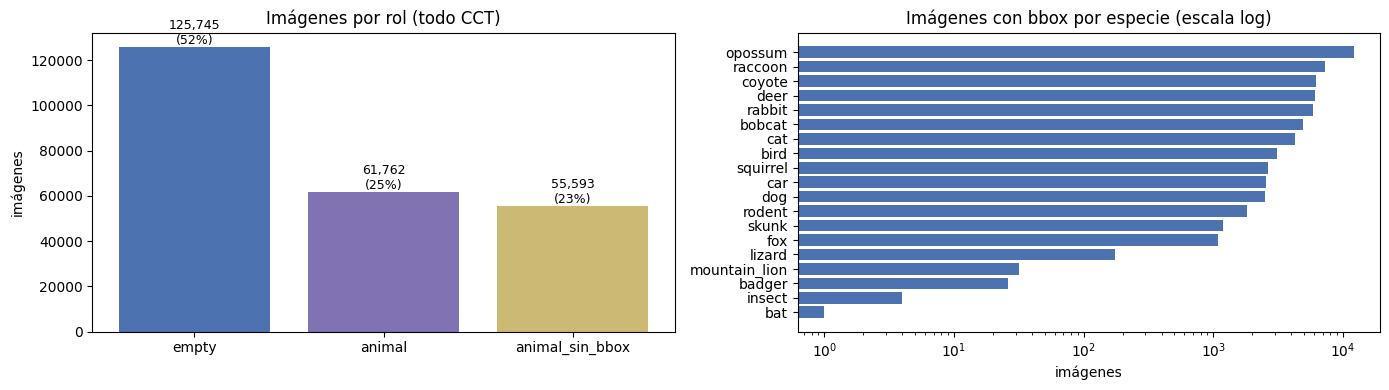

               cajas  imagenes
cat                           
opossum        12134     12067
raccoon         7908      7255
coyote          6505      6202
deer            6428      6055
rabbit          6025      5864
bobcat          5048      4927
cat             4391      4261
bird            4026      3103
squirrel        2648      2630
car             2557      2557
dog             2860      2490
rodent          1842      1829
skunk           1198      1192
fox             1099      1092
lizard           177       175
mountain_lion     44        32
badger            28        26
insect             7         4
bat                1         1

Razón de desbalance (máx/mín imágenes por clase): 12067x
Nota: las "animal_sin_bbox" NO se usarán (no se sabe dónde está el animal).


In [ ]:
train_locs = set(map(str, splits['eccv_train']))
trans_locs = set(map(str, splits['eccv_val']))
assert not (train_locs & trans_locs), 'eccv_train y eccv_val comparten ubicaciones'

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
rc = imgs['role'].value_counts()
ax[0].bar(rc.index, rc.values, color=['#4C72B0', '#8172B3', '#CCB974'][:len(rc)])
for i, v in enumerate(rc.values):
    ax[0].text(i, v, f'{v:,}\n({v/len(imgs):.0%})', ha='center', va='bottom', fontsize=9)
ax[0].set_title('Imágenes por rol (todo CCT)')
ax[0].set_ylabel('imágenes')

per_cls = bb_ann.groupby('cat').agg(cajas=('key', 'size'), imagenes=('key', 'nunique')).sort_values('imagenes')
ax[1].barh(per_cls.index, per_cls['imagenes'], color='#4C72B0')
ax[1].set_xscale('log')
ax[1].set_title('Imágenes con bbox por especie (escala log)')
ax[1].set_xlabel('imágenes')
plt.tight_layout(); plt.show()
print(per_cls.sort_values('imagenes', ascending=False).to_string())
print(f"\nRazón de desbalance (máx/mín imágenes por clase): {per_cls['imagenes'].max() / per_cls['imagenes'].min():.0f}x")
print('Nota: las "animal_sin_bbox" NO se usarán (no se sabe dónde está el animal).')

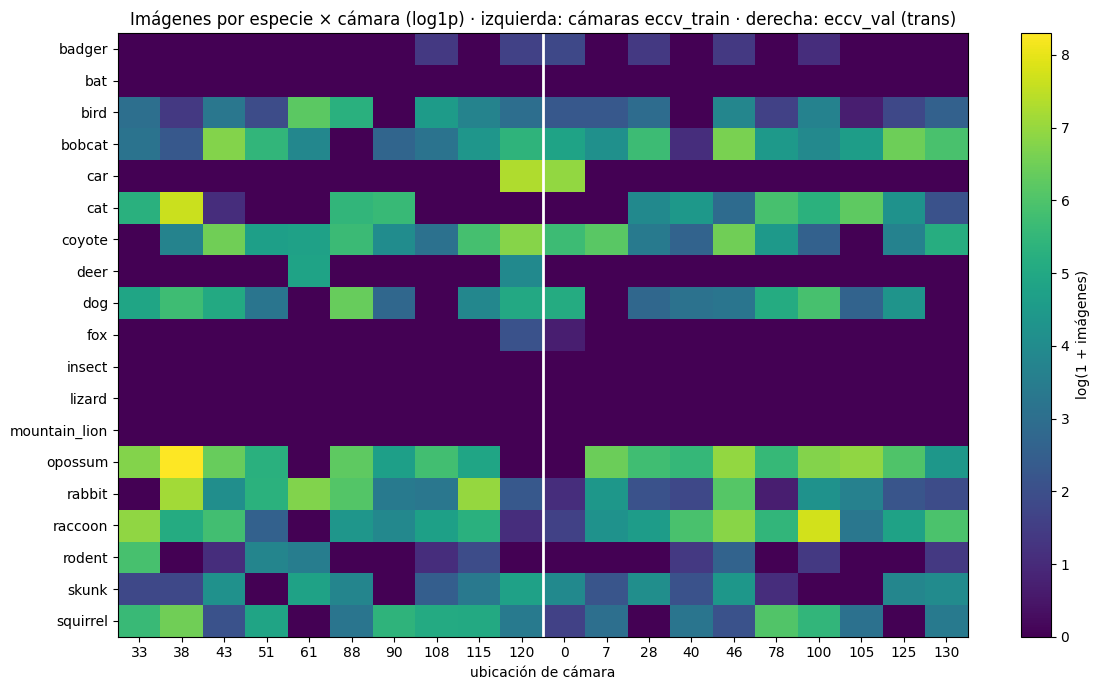

Número de cámaras (de las particiones oficiales) donde aparece cada especie:
cat
bat               0
mountain_lion     0
insect            0
lizard            0
fox               2
car               2
deer              2
badger            6
rodent           10
cat              13
skunk            16
dog              16
opossum          17
squirrel         17
coyote           18
bird             18
raccoon          19
rabbit           19
bobcat           19


In [ ]:
# Especificidad de cada especie por cámara -> pista de memorización de fondo
bx = bb_ann.merge(imgs[['key', 'location']].drop_duplicates('key'), on='key')
piv = bx.groupby(['cat', 'location']).key.nunique().unstack(fill_value=0)
cols = sorted([c for c in piv.columns if c in train_locs], key=int) + sorted([c for c in piv.columns if c in trans_locs], key=int)
piv = piv[cols]
fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(np.log1p(piv.values), aspect='auto', cmap='viridis')
ax.set_yticks(range(len(piv))); ax.set_yticklabels(piv.index)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols)
ax.axvline(len([c for c in cols if c in train_locs]) - 0.5, color='white', lw=2)
ax.set_title('Imágenes por especie × cámara (log1p) · izquierda: cámaras eccv_train · derecha: eccv_val (trans)')
ax.set_xlabel('ubicación de cámara')
plt.colorbar(im, label='log(1 + imágenes)')
plt.tight_layout(); plt.show()
n_loc_per_species = (piv > 0).sum(axis=1)
print('Número de cámaras (de las particiones oficiales) donde aparece cada especie:')
print(n_loc_per_species.sort_values().to_string())

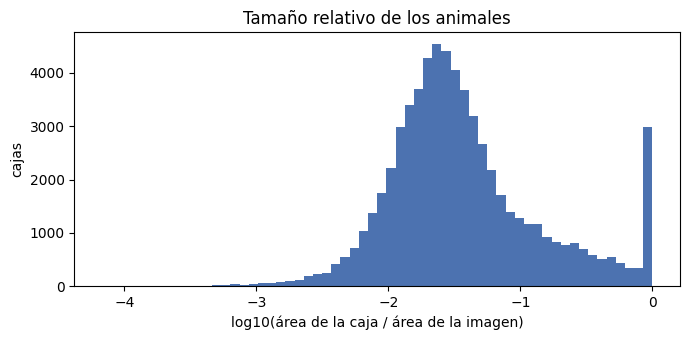

Cajas con < 1% del área de la imagen: 11.7% · < 0.25%: 1.1%


In [ ]:
# Tamaño relativo de los animales (fracción del área de la imagen)
if {'width', 'height'}.issubset(bb_imgs.columns):
    wh = bb_imgs.drop_duplicates('key').set_index('key')[['width', 'height']]
    t = bb_ann[['key', 'bbox', 'cat']].join(wh, on='key').dropna(subset=['width', 'height'])
    b = np.array(t['bbox'].tolist(), dtype=float)
    rel = (b[:, 2] * b[:, 3]) / (1.0 if BBOX_NORMALIZED else (t['width'] * t['height']).values)
    rel = np.clip(rel, 1e-6, 1)
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.hist(np.log10(rel), bins=60, color='#4C72B0')
    ax.set_xlabel('log10(área de la caja / área de la imagen)'); ax.set_ylabel('cajas')
    ax.set_title('Tamaño relativo de los animales')
    plt.tight_layout(); plt.show()
    print(f'Cajas con < 1% del área de la imagen: {(rel < 0.01).mean():.1%} · < 0.25%: {(rel < 0.0025).mean():.1%}')
else:
    print('El JSON de bboxes no trae width/height; se omite el análisis de tamaño.')

## 5. Construcción de particiones (por cámara y por secuencia)
| Partición | Cámaras | Qué mide |
|---|---|---|
| `train` | `eccv_train` | — |
| `cis_val` | `eccv_train` (secuencias reservadas) | generalización **dentro** de las mismas cámaras |
| `trans_val` | `eccv_val` | generalización a **cámaras nunca vistas** |

Regla de uso: `cis_val` sirve para elegir *epoch* y umbrales. `trans_val` se usa solo para reportar.

In [ ]:
U_ = imgs[imgs['role'].isin(['animal', 'empty'])].copy()

def sample_sequences(df, max_images):
    """Muestrea secuencias completas hasta acumular ~max_images imágenes."""
    if len(df) == 0:
        return df
    sizes = df.groupby('seq_key').size()
    order = rng.permutation(sizes.index.values)
    keep, total = [], 0
    for s in order:
        if total >= max_images:
            break
        keep.append(s); total += sizes[s]
    return df[df['seq_key'].isin(keep)]

parts = {'train': [], 'cis_val': [], 'trans_val': []}
for loc in sorted(train_locs, key=int):
    d = U_[U_['location'] == loc]
    if len(d) == 0:
        continue
    seqs = d['seq_key'].unique()
    n_cis = max(1, int(len(seqs) * CFG['CIS_FRAC']))
    cis_seqs = set(rng.choice(seqs, size=n_cis, replace=False))
    d_cis, d_tr = d[d['seq_key'].isin(cis_seqs)], d[~d['seq_key'].isin(cis_seqs)]
    an = sample_sequences(d_tr[d_tr['role'] == 'animal'], CFG['MAX_ANIMAL_PER_LOC'])
    n_emp = int(CFG['EMPTY_FRAC_TRAIN'] / (1 - CFG['EMPTY_FRAC_TRAIN']) * len(an))
    em = sample_sequences(d_tr[d_tr['role'] == 'empty'], n_emp)
    parts['train'].append(pd.concat([an, em]))
    parts['cis_val'].append(sample_sequences(d_cis, CFG['EVAL_MAX_PER_LOC']))
for loc in sorted(trans_locs, key=int):
    d = U_[U_['location'] == loc]
    if len(d):
        parts['trans_val'].append(sample_sequences(d, CFG['EVAL_MAX_PER_LOC']))

plan = []
for split, lst in parts.items():
    df = pd.concat(lst)
    df['split'] = split
    plan.append(df)
plan = pd.concat(plan, ignore_index=True)

summ = plan.groupby('split').agg(
    imagenes=('key', 'size'), con_animal=('n_boxes', lambda s: (s > 0).sum()),
    camaras=('location', 'nunique'), secuencias=('seq_key', 'nunique'))
summ['frac_vacias'] = 1 - summ['con_animal'] / summ['imagenes']
print(summ)
assert set(plan[plan.split == 'trans_val'].location).isdisjoint(set(plan[plan.split != 'trans_val'].location)), 'Fuga de cámaras'
assert set(plan[plan.split == 'train'].seq_key).isdisjoint(set(plan[plan.split == 'cis_val'].seq_key)), 'Fuga de secuencias'
print('OK: sin cámaras compartidas con trans_val ni secuencias compartidas entre train y cis_val')

           imagenes  con_animal  camaras  secuencias  frac_vacias
split                                                            
cis_val        3875        3566       10        1765     0.079742
train         14065       12632       10        6378     0.101884
trans_val      9895        9014       10        4425     0.089035
OK: sin cámaras compartidas con trans_val ni secuencias compartidas entre train y cis_val


## 6. Descarga + reducción a 640 px + etiquetas YOLO
Se descargan **solo** las imágenes del plan desde el bucket público de LILA y se escriben `images/<split>/loc<ID>__<archivo>.jpg` y `labels/<split>/...txt` (clase, x_c, y_c, w, h normalizados). El nombre incluye la cámara para poder agregar por ubicación en el posprocesamiento.

In [ ]:
session = requests.Session()
session.mount('https://', requests.adapters.HTTPAdapter(pool_connections=64, pool_maxsize=64, max_retries=3))

def img_url(file_name):
    fn = file_name[len('cct_images/'):] if file_name.startswith('cct_images/') else file_name
    return IMG_BASE + fn

# prueba de humo con una imagen
test_url = img_url(plan.iloc[0]['file_name'])
r = session.head(test_url, timeout=30)
print(test_url, '->', r.status_code)
assert r.status_code == 200, 'No se pudo acceder a la imagen de prueba: revisa IMG_BASE / file_name'

for sp in parts:
    (LOCAL / 'images' / sp).mkdir(parents=True, exist_ok=True)
    (LOCAL / 'labels' / sp).mkdir(parents=True, exist_ok=True)

def process(row):
    out_name = f"loc{row['location']}__{row['key']}"
    img_dst = LOCAL / 'images' / row['split'] / out_name
    lab_dst = LOCAL / 'labels' / row['split'] / (Path(out_name).stem + '.txt')
    if img_dst.exists() and lab_dst.exists():
        return 'ok', out_name
    try:
        r = session.get(img_url(row['file_name']), timeout=60)
        r.raise_for_status()
        im = Image.open(io.BytesIO(r.content)).convert('RGB')
    except Exception as e:
        return 'fail', f'{out_name}: {e}'
    W, H = im.size
    lines = []
    for cat, (x, y, w, h) in boxes.get(row['key'], []):
        if BBOX_NORMALIZED:
            x, y, w, h = x * W, y * H, w * W, h * H
        x1, y1, x2, y2 = max(0, x), max(0, y), min(W, x + w), min(H, y + h)
        if (x2 - x1) < 2 or (y2 - y1) < 2:
            continue
        lines.append(f'{CLS_ID[cat]} {(x1+x2)/2/W:.6f} {(y1+y2)/2/H:.6f} {(x2-x1)/W:.6f} {(y2-y1)/H:.6f}')
    if row['role'] == 'animal' and not lines:
        return 'drop', out_name
    sc = CFG['MAX_SIDE'] / max(W, H)
    if sc < 1:
        im = im.resize((round(W * sc), round(H * sc)), Image.BILINEAR)
    im.save(img_dst, quality=90)
    lab_dst.write_text('\n'.join(lines))
    return 'ok', out_name

records = plan[['file_name', 'key', 'location', 'split', 'role']].to_dict('records')
status = []
with ThreadPoolExecutor(CFG['N_WORKERS']) as ex:
    for res in tqdm(ex.map(process, records), total=len(records)):
        status.append(res)
st = pd.Series([s for s, _ in status]).value_counts()
print(st.to_dict())
fails = [m for s, m in status if s == 'fail']
if fails:
    print('Ejemplos de fallos:', fails[:5])

https://storage.googleapis.com/public-datasets-lila/caltech-unzipped/cct_images/5a096c23-23d2-11e8-a6a3-ec086b02610b.jpg -> 200


  0%|          | 0/27835 [00:00<?, ?it/s]

{'ok': 27835}


## 7. Metadatos finales, `data.yaml` y verificación

In [ ]:
ok_names = {m for s, m in status if s == 'ok'}
plan['file'] = 'loc' + plan['location'] + '__' + plan['key']
meta = plan[plan['file'].isin(ok_names)].copy()
meta['species'] = meta['key'].map(lambda k: '|'.join(sorted({c for c, _ in boxes.get(k, [])})))
meta['n_boxes'] = meta['key'].map(lambda k: len(boxes.get(k, [])))
meta = meta[['file', 'split', 'location', 'seq_key', 'datetime', 'role', 'species', 'n_boxes']]
meta.to_csv(META_DIR / 'meta.csv', index=False)
print(meta.groupby('split').size())

# estadísticas reales a partir de las etiquetas escritas
U.load_classes()
inst = pd.DataFrame({sp: U.count_instances(sp) for sp in parts}).fillna(0).astype(int)
inst = inst.reindex(CLASSES).fillna(0).astype(int)
print('\nInstancias por clase y partición:')
print(inst.to_string())
inst.to_csv(META_DIR / 'instancias_por_clase.csv')

yml = U.make_yaml('data', train='images/train', val='images/cis_val')
print('\nYAML:', yml)
print(Path(yml).read_text()[:400])

split
cis_val       3875
train        14065
trans_val     9895
dtype: int64

Instancias por clase y partición:
               train  cis_val  trans_val
badger             5        2         10
bat                0        0          0
bird            1058      190         70
bobcat           904      236       1473
car              752      216        611
cat              855      326        728
coyote          1631      409        932
deer             128       38          0
dog              817      200        448
fox                3        2          0
insect             0        0          0
lizard             0        0          0
mountain_lion      0        0          0
opossum         2404      893       2415
rabbit          2257      592        185
raccoon         1172      309       1881
rodent           264       59          6
skunk            259       61        201
squirrel         845      214        396

YAML: /content/cct/data.yaml
path: /content/cct
train: images/train


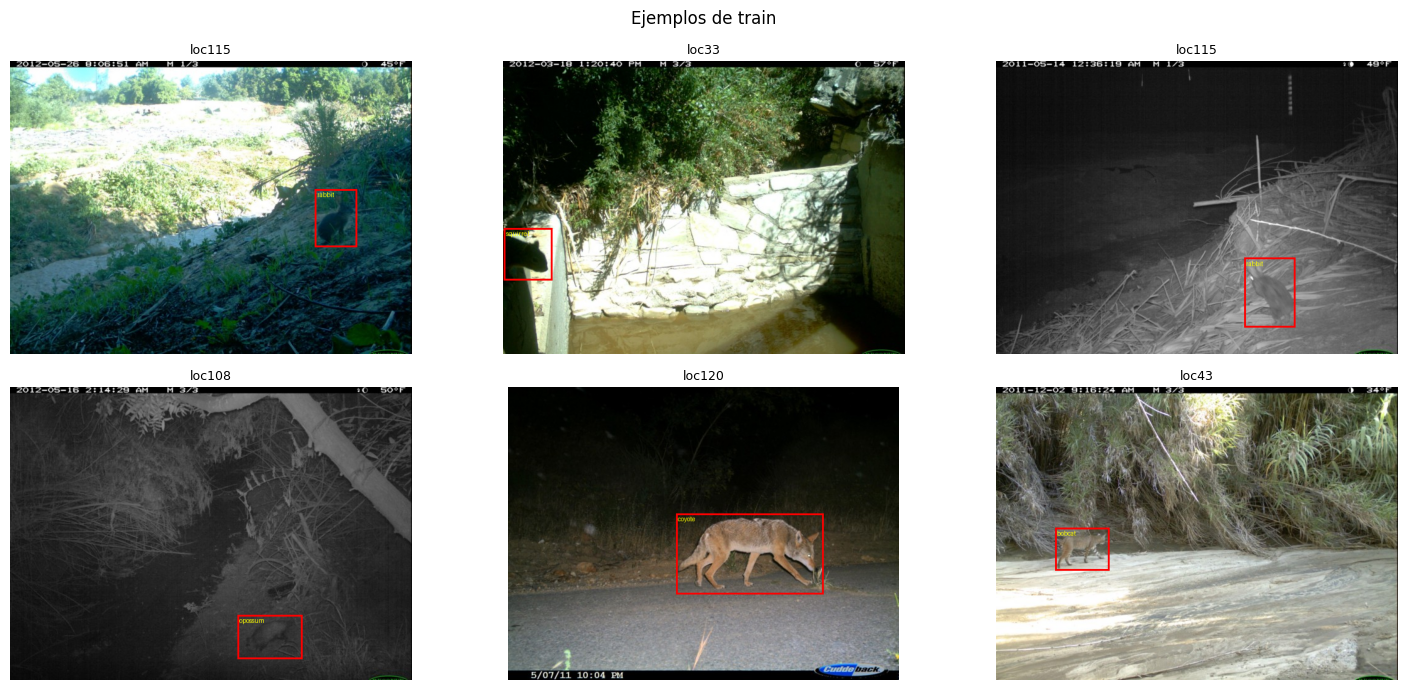

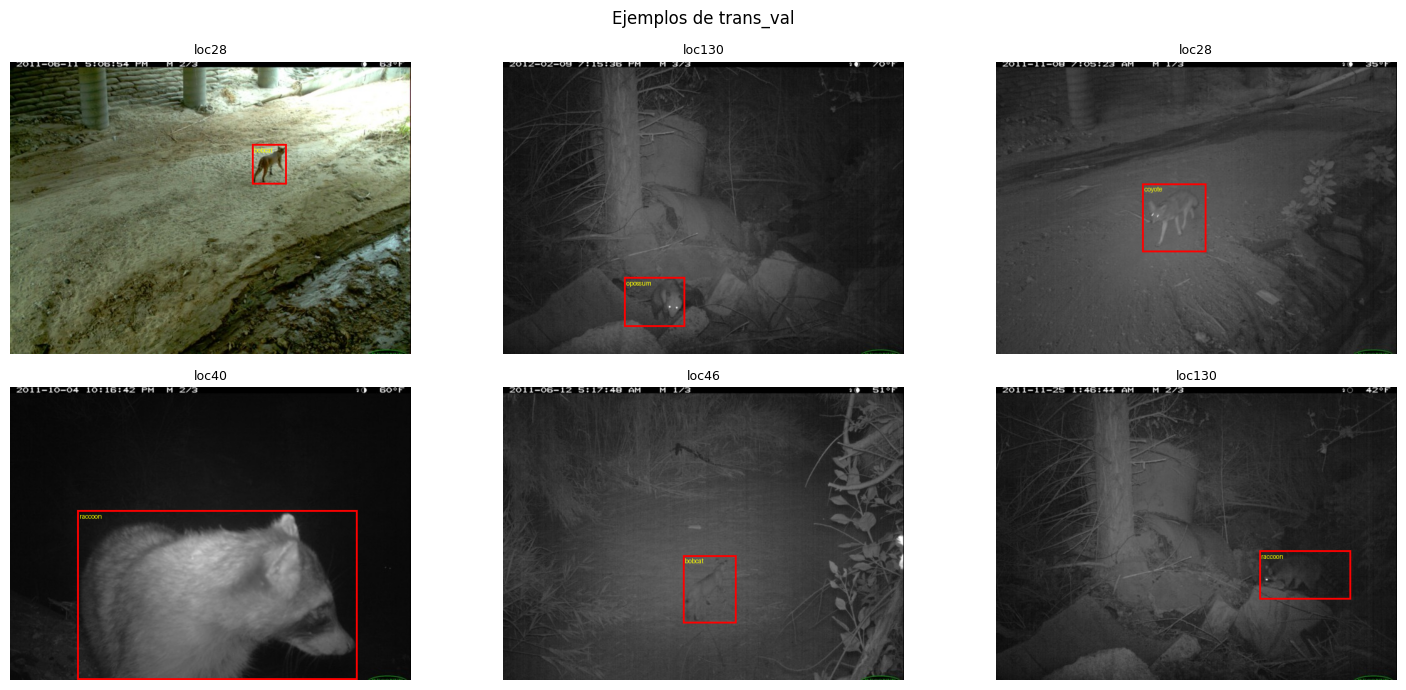

In [ ]:
# Vista previa con cajas
def preview(split, n=6):
    fs = meta[(meta.split == split) & (meta.n_boxes > 0)].sample(n, random_state=1)['file'].tolist()
    fig, axs = plt.subplots(2, n // 2, figsize=(15, 7))
    for a, f in zip(axs.ravel(), fs):
        im = Image.open(LOCAL / 'images' / split / f).convert('RGB')
        W, H = im.size
        d = ImageDraw.Draw(im)
        for l in (LOCAL / 'labels' / split / (Path(f).stem + '.txt')).read_text().splitlines():
            c, xc, yc, w, h = l.split(); xc, yc, w, h = map(float, (xc, yc, w, h))
            d.rectangle([(xc - w/2) * W, (yc - h/2) * H, (xc + w/2) * W, (yc + h/2) * H], outline='red', width=3)
            d.text(((xc - w/2) * W + 3, (yc - h/2) * H + 3), CLASSES[int(c)], fill='yellow')
        a.imshow(im); a.axis('off'); a.set_title(f.split('__')[0], fontsize=9)
    plt.suptitle(f'Ejemplos de {split}'); plt.tight_layout(); plt.show()

preview('train'); preview('trans_val')

## 8. Guardar copia en Drive
Un `.tar` sin compresión permite restaurar el dataset en segundos en sesiones futuras (los notebooks 02-04 lo hacen automáticamente).

In [ ]:
if CFG['SAVE_TAR_TO_DRIVE']:
    tar = DRIVE_DIR / 'cct_dataset.tar'
    subprocess.run(['tar', '-cf', str(tar), '-C', str(LOCAL), 'images', 'labels'], check=True)
    print(f'Guardado {tar} ({tar.stat().st_size / 1e9:.2f} GB). Recuerda: Drive gratuito tiene 15 GB.')
print('Listo. Continúa con el notebook 02.')

Guardado /content/drive/MyDrive/Dfoto/cct_dataset.tar (2.12 GB). Recuerda: Drive gratuito tiene 15 GB.
Listo. Continúa con el notebook 02.
